In [12]:
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
src_dir = cwd / "src" if (cwd / "src").exists() else cwd.parent / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from utils.data_processing import (
    extract_condition, 
    extract_day,
    extract_magnification
)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

COND_ORDER = ["static", "perfusion"]
CONDITION_PALETTE = {"static": "#2E86AB", "perfusion": "#A23B72"}
MIN_MAX_NUCLEI_VOLUME = (500, 6500) #seems safe after exploring the volume distribution

In [13]:
# Notebook runs from notebooks/, so results is one level up
results_dir = Path("../ki67_results").resolve()
output_dir = results_dir / "processed_csvs"
output_file = output_dir / "processed_ki67.csv"

# Find every CSV under results/ recursively, excluding the final output file if it already exists
csv_files = sorted(
    csv_path
    for csv_path in results_dir.rglob("*.csv")
    if csv_path.resolve() != output_file.resolve()
)

if not csv_files:
    raise FileNotFoundError(f"No CSV files found under {results_dir}")

# Read and merge all CSV files
merged_df = pd.concat((pd.read_csv(csv_file) for csv_file in csv_files), ignore_index=True)

# Extract 'condition', 'day' and 'magnification' metadata columns and store them
merged_df["condition"] = merged_df["lif_container_id"].apply(extract_condition)
merged_df["day"] = merged_df["lif_image_name"].apply(extract_day)
merged_df["magnification"] = merged_df["lif_image_name"].apply(extract_magnification)

# Ensure output directory exists and save merged CSV (unfiltered)
output_dir.mkdir(parents=True, exist_ok=True)
merged_df.to_csv(output_file, index=False)

print(f"Merged {len(csv_files)} CSV files into: {output_file}")
print(f"Merged dataframe shape: {merged_df.shape}")
merged_df.head()

Merged 32 CSV files into: C:\Users\adiez_cmic\github_repos\margrecs_alginate\ki67_results\processed_csvs\processed_ki67.csv
Merged dataframe shape: (85924, 34)


,lif_container_id,lif_image_name,label,centroid-0,centroid-1,centroid-2,area,area_bbox,area_filled,equivalent_diameter_area,...,F-Actin_sum_int,ki67_mean_int,ki67_min_int,ki67_max_int,ki67_std_int,ki67_sum_int,input_img_shape,condition,day,magnification
0,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,1,8.758796,11.897715,6.305767,2757.0,9025.0,2757.0,17.397201,...,88893.0,13.816830,0.0,69.0,11.534976,38093.0,"[107, 1024, 1024]",perfusion,14,10
1,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,2,27.742657,23.812587,4.513986,1430.0,6120.0,1430.0,13.978025,...,11083.0,1.820280,0.0,13.0,2.232752,2603.0,"[107, 1024, 1024]",perfusion,14,10
2,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,3,7.442077,25.631158,6.420107,1502.0,5580.0,1502.0,14.208790,...,30722.0,9.438748,0.0,45.0,6.745708,14177.0,"[107, 1024, 1024]",perfusion,14,10
3,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,4,31.826923,32.365385,0.846154,52.0,336.0,52.0,4.630930,...,303.0,1.307692,0.0,8.0,1.834902,68.0,"[107, 1024, 1024]",perfusion,14,10
4,A549-perfusion-day3andday14,D14-E-10x-zoom1.5-2,5,1.889573,21.681856,6.771346,2436.0,5040.0,2436.0,16.693967,...,124966.0,19.988916,0.0,74.0,12.105833,48693.0,"[107, 1024, 1024]",perfusion,14,10


In [ ]:
# Filter out rows where area is below 500 or above 6500
filtered_df = merged_df[(merged_df["area"] >= MIN_MAX_NUCLEI_VOLUME[0]) & (merged_df["area"] <= MIN_MAX_NUCLEI_VOLUME[1])]

# Percentile-based filtering for ki67_mean_int (between 1st and 99th percentiles)
ki67_lower = np.percentile(filtered_df["ki67_mean_int"], 1)
ki67_upper = np.percentile(filtered_df["ki67_mean_int"], 99)

filtered_df = filtered_df[
    (filtered_df["ki67_mean_int"] >= ki67_lower) &
    (filtered_df["ki67_mean_int"] <= ki67_upper)
]

# Filter out rows where magnification is different to 10x (avoid mixing different magnification levels)
filtered_df = filtered_df[filtered_df["magnification"] == 10]

# Assign filtered_df to merged_df to ensure all plots use the same source of truth
merged_df = filtered_df

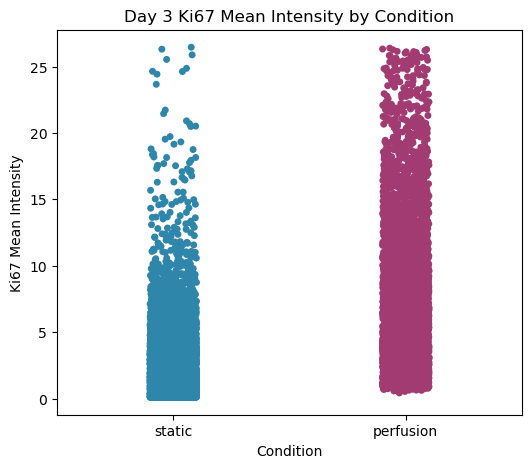

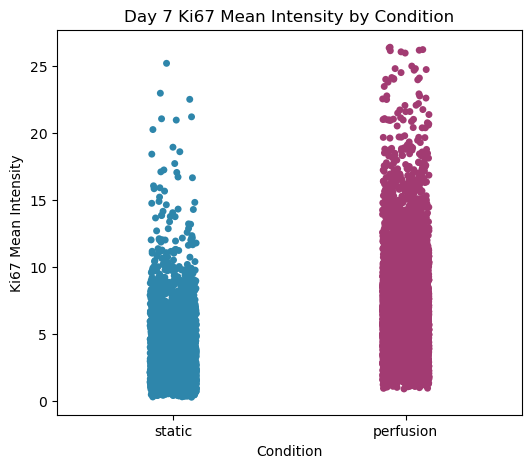

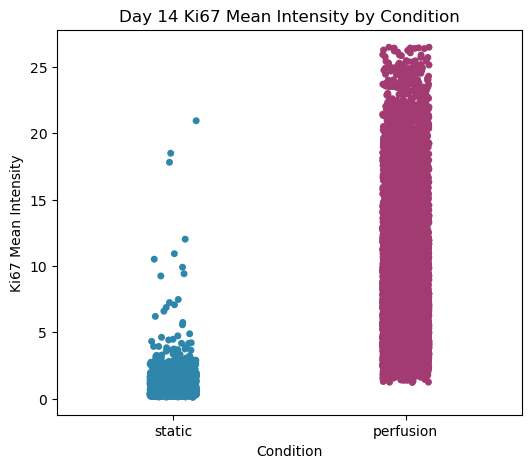

In [15]:
# Loop over days 3, 7, and 14 and produce the strip plots for each day
for day in [3, 7, 14]:
    df_day = merged_df[merged_df["day"] == day]

    plt.figure(figsize=(6, 5))
    ax = sns.stripplot(
        data=df_day,
        x="condition",
        y="ki67_mean_int",
        hue="condition",
        order=COND_ORDER,
        hue_order=COND_ORDER,
        palette=CONDITION_PALETTE,
        dodge=False
    )
    ax.set_title(f"Day {day} Ki67 Mean Intensity by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Ki67 Mean Intensity")
    plt.show()

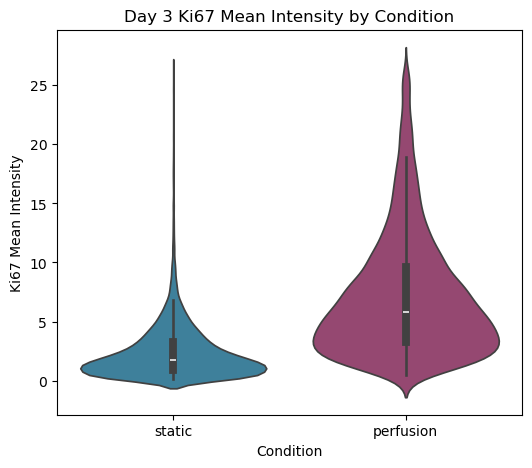

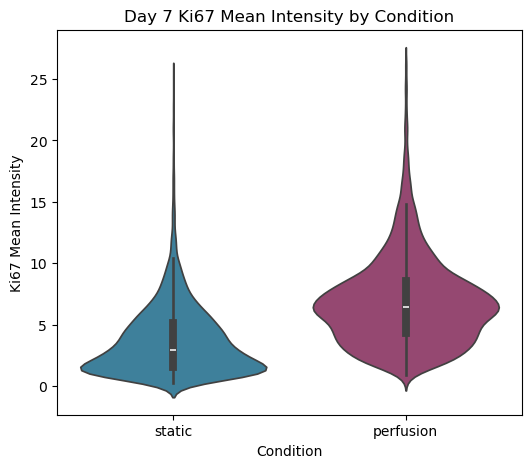

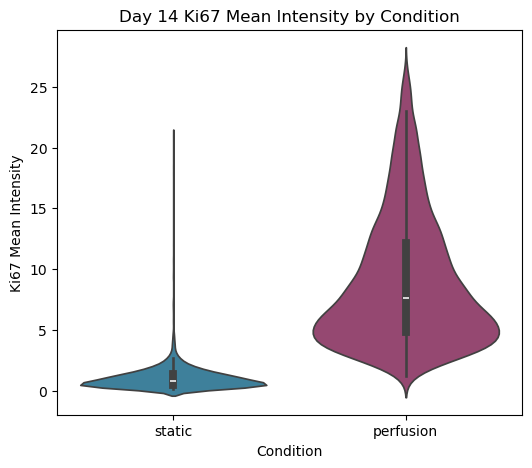

In [16]:
# Loop over days 3, 7, and 14 and produce the violin plots for each day
for day in [3, 7, 14]:
    df_day = merged_df[merged_df["day"] == day]

    plt.figure(figsize=(6, 5))
    ax = sns.violinplot(
        data=df_day,
        x="condition",
        y="ki67_mean_int",
        hue="condition",
        order=COND_ORDER,
        hue_order=COND_ORDER,
        palette=CONDITION_PALETTE,
        legend=False,
        dodge=False
    )
    ax.set_title(f"Day {day} Ki67 Mean Intensity by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Ki67 Mean Intensity")
    plt.show()

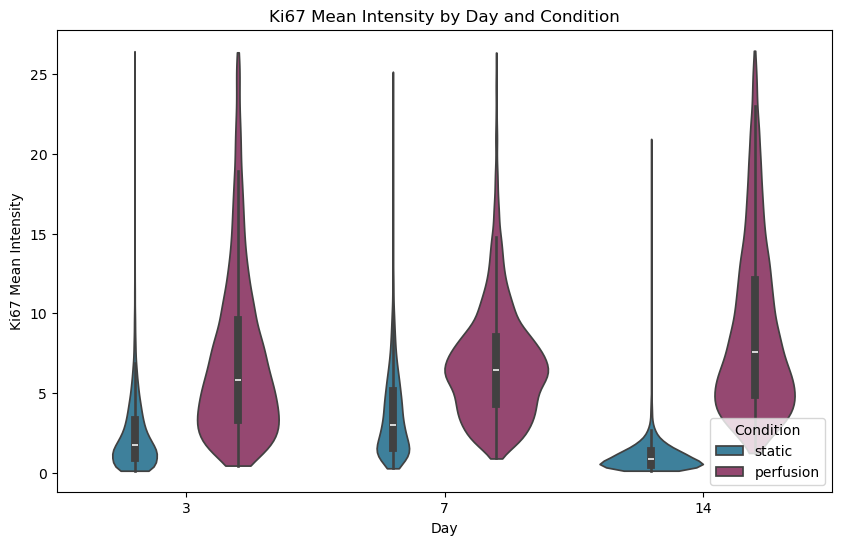

In [17]:
# Plot violin plots for days 3, 7, and 14 side by side, grouping by day (force int x axis)
plt.figure(figsize=(10, 6))
df_violin = merged_df[merged_df["day"].isin([3, 7, 14])].copy()
df_violin["day"] = df_violin["day"].astype(int)  # ensure day is int not float

ax = sns.violinplot(
    data=df_violin,
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True,
    cut=0
)
ax.set_title("Ki67 Mean Intensity by Day and Condition")
ax.set_xlabel("Day")
ax.set_ylabel("Ki67 Mean Intensity")
plt.legend(title="Condition")
plt.show()

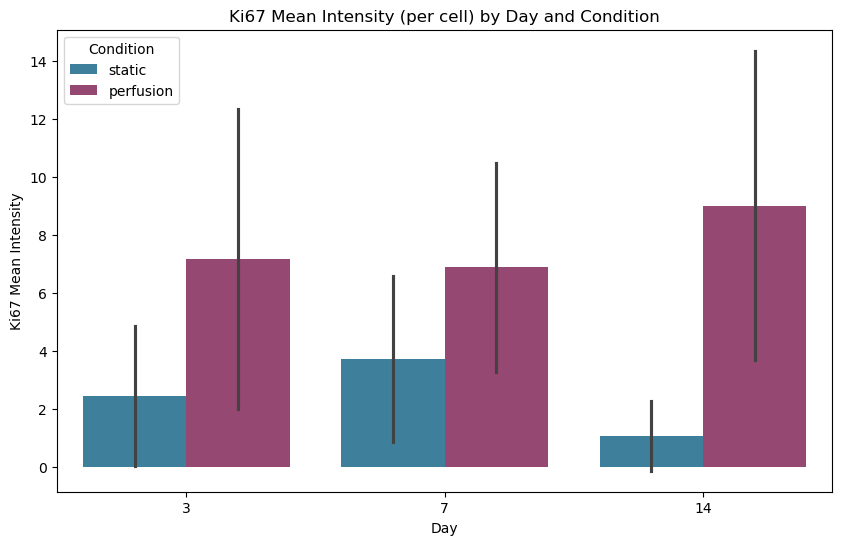

In [18]:
# Plot bar plots for days 3, 7, and 14 side by side, grouping by day, with standard deviation error bars
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=merged_df[merged_df["day"].isin([3, 7, 14])],
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True,
    errorbar="sd"  # For seaborn >= 0.12; otherwise, ci="sd" is enough
)
ax.set_title("Ki67 Mean Intensity (per cell) by Day and Condition")
ax.set_xlabel("Day")
ax.set_ylabel("Ki67 Mean Intensity")
plt.legend(title="Condition")
plt.show()

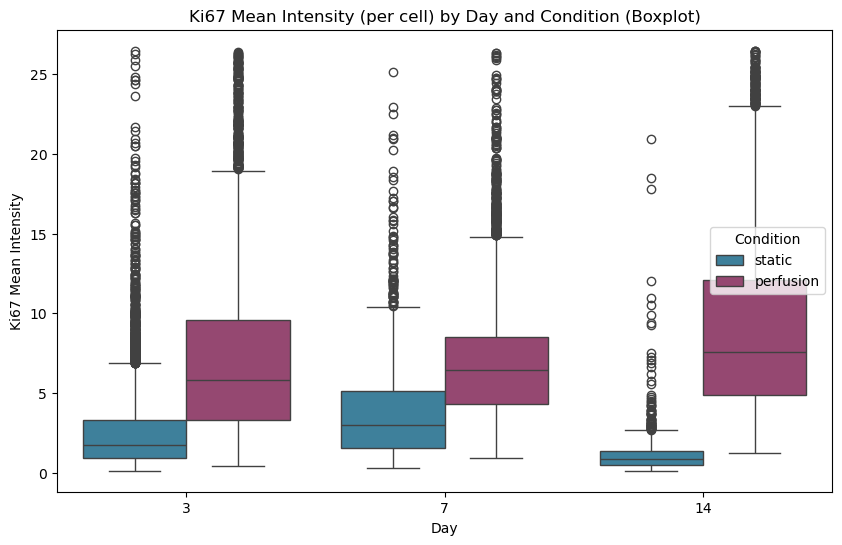

In [19]:
# Plot boxplots for days 3, 7, and 14 side by side, grouping by day and condition
plt.figure(figsize=(10, 6))
ax = sns.boxplot(
    data=merged_df[merged_df["day"].isin([3, 7, 14])],
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True
)
ax.set_title("Ki67 Mean Intensity (per cell) by Day and Condition (Boxplot)")
ax.set_xlabel("Day")
ax.set_ylabel("Ki67 Mean Intensity")
plt.legend(title="Condition")
plt.show()

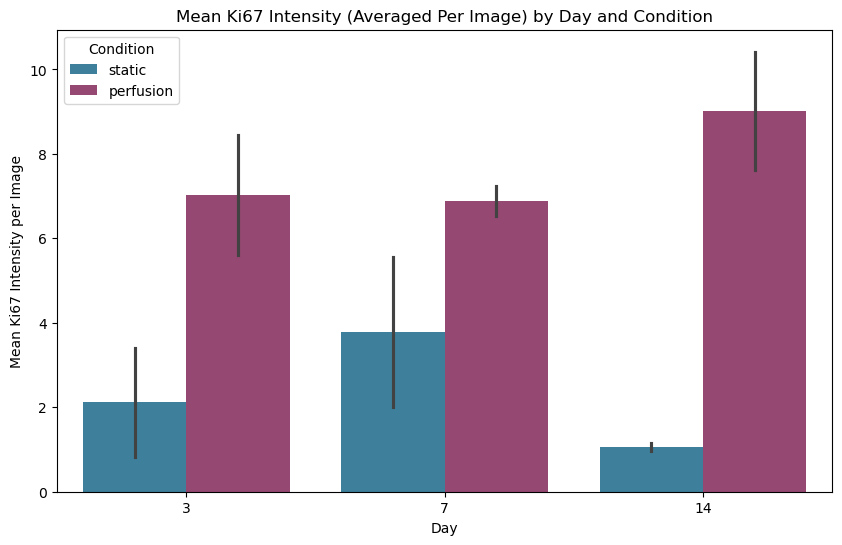

In [20]:
# Group the dataframe and average 'ki67_mean_int' per image, then plot bar plots (mean ± sd) by day/condition.
grouped_df = (
    merged_df
    .groupby(['lif_container_id', 'lif_image_name', 'condition', 'day'], as_index=False)
    .agg({'ki67_mean_int': 'mean'})
)

filtered_df = grouped_df[grouped_df["day"].isin([3, 7, 14])].copy()
filtered_df["day"] = filtered_df["day"].astype(int)  # ensure day is int

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=filtered_df,
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True,
    errorbar="sd"  # For seaborn >= 0.12; otherwise, ci="sd" is enough
)
ax.set_title("Mean Ki67 Intensity (Averaged Per Image) by Day and Condition")
ax.set_xlabel("Day")
ax.set_ylabel("Mean Ki67 Intensity per Image")
plt.legend(title="Condition")
plt.show()

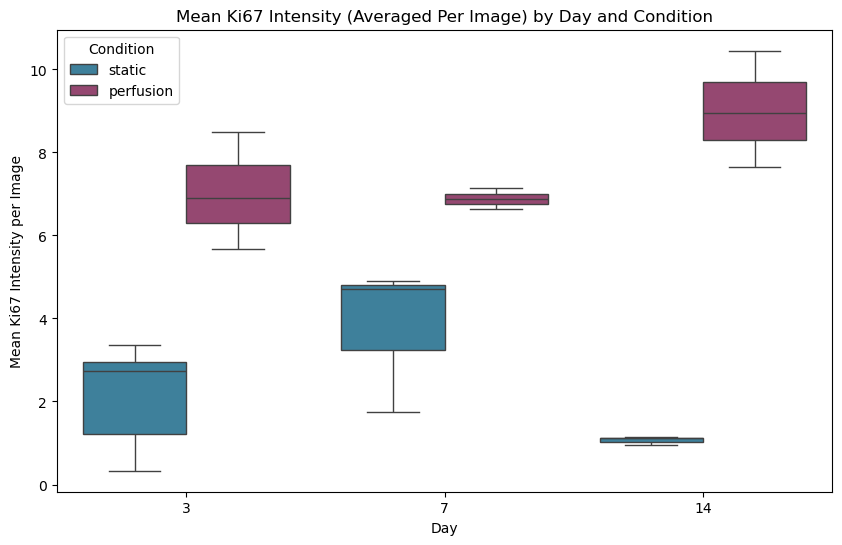

In [21]:
# Group the dataframe and average 'ki67_mean_int' per image, then plot boxplots by day/condition.
grouped_df = (
    merged_df
    .groupby(['lif_container_id', 'lif_image_name', 'condition', 'day'], as_index=False)
    .agg({'ki67_mean_int': 'mean'})
)

filtered_df = grouped_df[ grouped_df["day"].isin([3, 7, 14]) ].copy()
filtered_df["day"] = filtered_df["day"].astype(int)  # ensure day is int

plt.figure(figsize=(10, 6))
ax = sns.boxplot(
    data=filtered_df,
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True
)
ax.set_title("Mean Ki67 Intensity (Averaged Per Image) by Day and Condition")
ax.set_xlabel("Day")
ax.set_ylabel("Mean Ki67 Intensity per Image")
plt.legend(title="Condition")
plt.show()

C:\Users\adiez_cmic\AppData\Local\Temp\ipykernel_37880\823681905.py:13: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  ax = sns.stripplot(


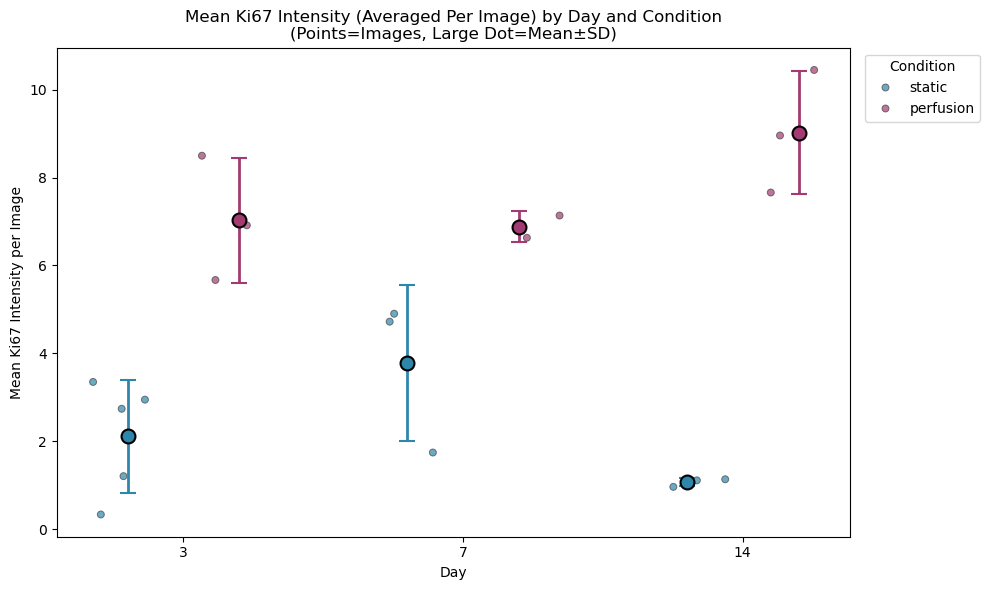

In [22]:
# Group the dataframe and average 'ki67_mean_int' per image.
grouped_df = (
    merged_df
    .groupby(['lif_container_id', 'lif_image_name', 'condition', 'day'], as_index=False)
    .agg({'ki67_mean_int': 'mean'})
)

filtered_df = grouped_df[grouped_df["day"].isin([3, 7, 14])].copy()
filtered_df["day"] = filtered_df["day"].astype(int)  # ensure day is int

plt.figure(figsize=(10, 6))
# Show individual data points (stripplot)
ax = sns.stripplot(
    data=filtered_df,
    x="day",
    y="ki67_mean_int",
    hue="condition",
    hue_order=COND_ORDER,
    palette=CONDITION_PALETTE,
    dodge=True,
    jitter=0.3,
    alpha=0.7,
    linewidth=0.7,
    edgecolor='gray'
)

# Now plot mean and SD as point with errorbar
# Calculate mean and SD for each group (day, condition)
summary = (
    filtered_df
    .groupby(['day', 'condition'])
    .agg(mean_val=('ki67_mean_int', 'mean'), sd_val=('ki67_mean_int', 'std'))
    .reset_index()
)

# Overlay the means and SD using scatter + errorbar
for i, cond in enumerate(COND_ORDER):
    cond_color = CONDITION_PALETTE[cond]
    for day in [3, 7, 14]:
        sub = summary[(summary.day == day) & (summary.condition == cond)]
        if not sub.empty:
            # Find correct x-position:
            # Use dodge to offset each condition
            n_conditions = len(COND_ORDER)
            base = [3, 7, 14].index(day)
            width = 0.8  # typical bar width in seaborn
            offset = (i - (n_conditions-1)/2) * (width / n_conditions)
            x_pos = base + offset
            mean = sub['mean_val'].values[0]
            sd = sub['sd_val'].values[0]
            ax.errorbar(
                x=x_pos,
                y=mean,
                yerr=sd,
                fmt='o',
                color=cond_color,
                capsize=6,
                lw=2,
                zorder=10,
                markersize=10,
                mec='black',
                mew=1.5
            )

ax.set_title("Mean Ki67 Intensity (Averaged Per Image) by Day and Condition\n(Points=Images, Large Dot=Mean±SD)")
ax.set_xlabel("Day")
ax.set_ylabel("Mean Ki67 Intensity per Image")
plt.legend(title="Condition", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()